# Pipeline complet : risque d'inondation sur route (V1, V2)

Ce notebook refait tout le pipeline étape par étape : **contrôle des données**, **découpage**, **traitement des variables**, **entraînement**, **test sur des orages jamais vus**, **évaluation** et **analyse**. Chaque étape a son schéma.

Les données sont synthétiques (`flood_risk/synth.py`) : les chiffres mesurent le pipeline, pas le système réel.

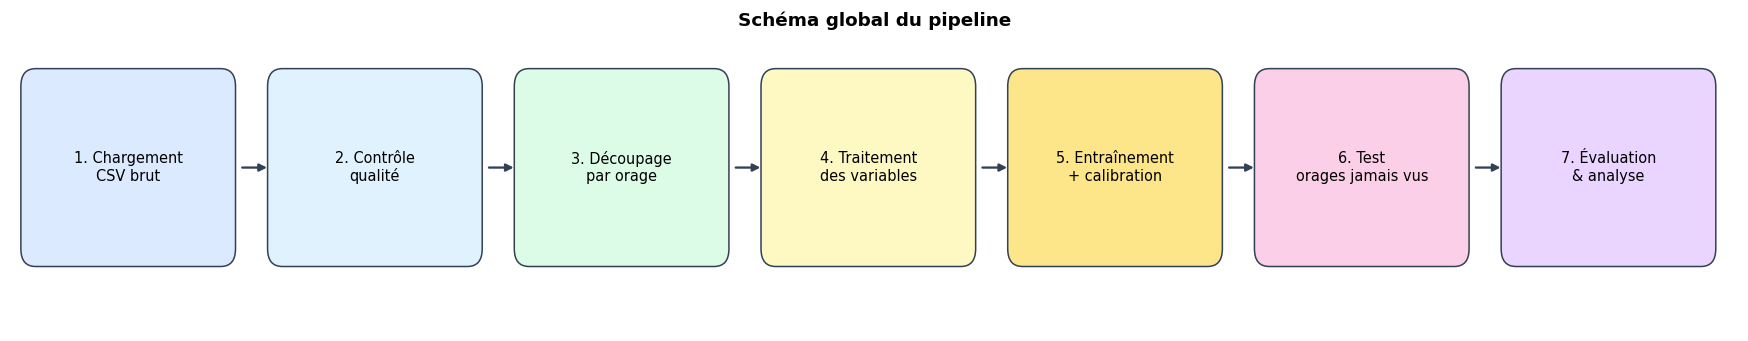

In [1]:
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mp
from matplotlib.colors import ListedColormap
from sklearn.model_selection import GroupKFold
from sklearn.isotonic import IsotonicRegression
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_curve, precision_recall_curve, roc_auc_score,
                             average_precision_score, brier_score_loss, confusion_matrix)

from flood_risk.schema import RAW_FEATURES, STATIC_FEATURES, DYNAMIC_FEATURES, LABEL, LEVELS
from flood_risk.features import engineer, drainage_vulnerability
from flood_risk import v1, v2
from flood_risk.predict import demo_route, score_route

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

def draw_flow(labels, title, colors=None, figsize=(16, 3.2)):
    colors = colors or ["#dbeafe", "#e0f2fe", "#dcfce7", "#fef9c3", "#fde68a", "#fbcfe8", "#e9d5ff"]
    fig, ax = plt.subplots(figsize=figsize)
    ax.axis("off"); ax.set_xlim(0, len(labels) * 2); ax.set_ylim(0, 2)
    for i, (lab, col) in enumerate(zip(labels, colors)):
        x = i * 2 + 0.1
        ax.add_patch(mp.FancyBboxPatch((x, 0.45), 1.7, 1.3, boxstyle="round,pad=0.02,rounding_size=0.12",
                                       fc=col, ec="#334155"))
        ax.text(x + 0.85, 1.1, lab, ha="center", va="center", fontsize=9.5)
        if i < len(labels) - 1:
            ax.annotate("", xy=(x + 2.0, 1.1), xytext=(x + 1.75, 1.1),
                        arrowprops=dict(arrowstyle="-|>", lw=1.5, color="#334155"))
    ax.set_title(title, fontsize=12, weight="bold")
    plt.tight_layout(); plt.show()

draw_flow(["1. Chargement\nCSV brut", "2. Contrôle\nqualité", "3. Découpage\npar orage",
           "4. Traitement\ndes variables", "5. Entraînement\n+ calibration", "6. Test\norages jamais vus",
           "7. Évaluation\n& analyse"],
          "Schéma global du pipeline")

## 1. Chargement et contrôle qualité

On vérifie les données avant tout calcul : doublons, valeurs manquantes, bornes physiques (une pluie ne peut pas être négative, une proportion reste entre 0 et 1), codes d'étiquette.

In [2]:
raw = pd.read_csv("data/inventory_synthetic.csv")
RAIN = ["rain_eta_mmh", "rain_1h_mm", "rain_3h_mm", "rain_24h_mm"]

checks = {
    "lignes": len(raw),
    "doublons (segment, orage, créneau)": int(raw.duplicated(["segment_id", "event_id", "slot_min"]).sum()),
    "valeurs manquantes": int(raw.isna().sum().sum()),
    "pluies négatives": int((raw[RAIN] < 0).sum().sum()),
    "osm_completeness hors [0, 1]": int(((raw.osm_completeness < 0) | (raw.osm_completeness > 1)).sum()),
    "impervious_frac hors [0, 1]": int(((raw.impervious_frac < 0) | (raw.impervious_frac > 1)).sum()),
    "étiquettes hors {0, 1}": int((~raw[LABEL].isin([0, 1])).sum()),
}
pd.Series(checks, name="contrôle").to_frame()

,contrôle
lignes,51200
"doublons (segment, orage, créneau)",0
valeurs manquantes,0
pluies négatives,0
"osm_completeness hors [0, 1]",0
"impervious_frac hors [0, 1]",0
"étiquettes hors {0, 1}",0


In [3]:
df = raw.drop_duplicates(["segment_id", "event_id", "slot_min"]).dropna().copy()
for c in RAIN:
    df[c] = df[c].clip(lower=0)
print(f"après nettoyage : {len(df):,} lignes (retirées : {len(raw) - len(df)})")

après nettoyage : 51,200 lignes (retirées : 0)


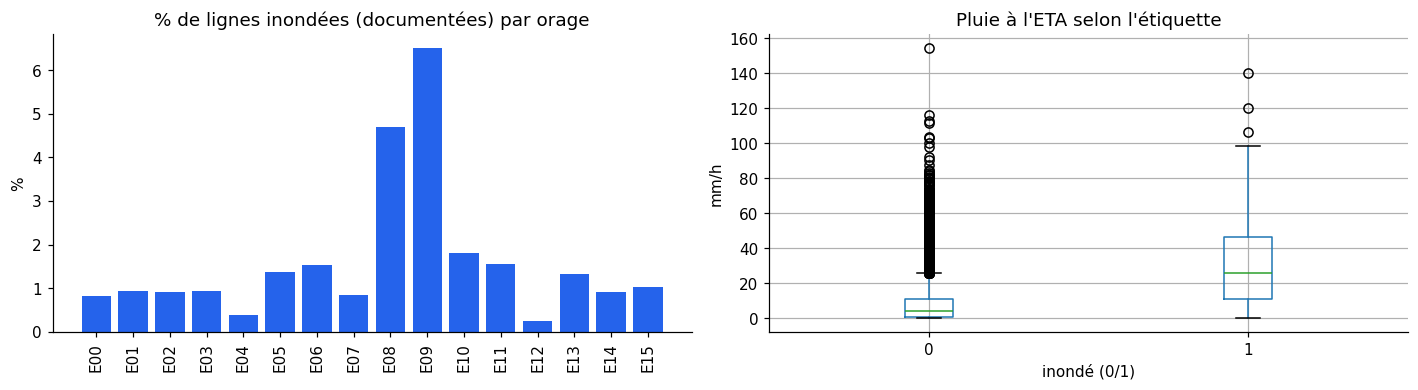

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
rate = df.groupby("event_id")[LABEL].mean() * 100
ax[0].bar(rate.index, rate.values, color="#2563eb")
ax[0].set(title="% de lignes inondées (documentées) par orage", ylabel="%")
ax[0].tick_params(axis="x", rotation=90)
df.boxplot(column="rain_eta_mmh", by=LABEL, ax=ax[1])
ax[1].set(title="Pluie à l'ETA selon l'étiquette", xlabel="inondé (0/1)", ylabel="mm/h")
plt.suptitle(""); plt.tight_layout(); plt.show()

**Lecture.** Les données sont propres (aucun doublon, aucune valeur manquante, bornes respectées) : le nettoyage ne retire rien. Le taux d'inondation varie fortement d'un orage à l'autre, et les lignes inondées ont une pluie à l'ETA nettement plus élevée. C'est le signal que le modèle doit apprendre, mais il est aussi très concentré sur quelques orages.

## 2. Découpage : entraînement, validation, test

Règle centrale : **un orage ne peut jamais être à la fois dans l'entraînement et dans le test**. Sinon le modèle apprend la pluie de cet orage et les scores sont trop optimistes.

- **Test** : les 4 derniers orages, mis de côté et utilisés une seule fois, à la fin.
- **Entraînement** : les 12 autres orages, découpés en 4 plis par orage pour la validation interne (calibration et seuils).

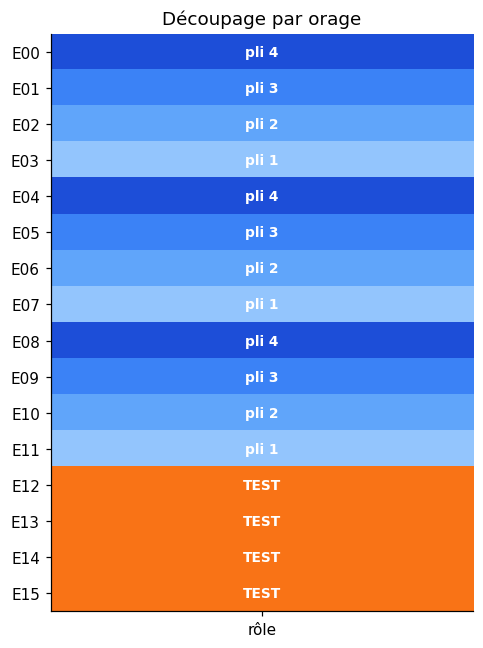

entraînement : 38,400 lignes, 12 orages
test         : 12,800 lignes, 4 orages (E12, E13, E14, E15)


In [5]:
events = sorted(df.event_id.unique())
test_events = events[-4:]
train_df = df[~df.event_id.isin(test_events)].reset_index(drop=True)
test_df = df[df.event_id.isin(test_events)].reset_index(drop=True)

fold_of = np.full(len(train_df), -1)
for k, (_, va) in enumerate(GroupKFold(n_splits=4).split(train_df, train_df[LABEL], train_df.event_id)):
    fold_of[va] = k

# Matrice orage × rôle : 0-3 = pli de validation, 4 = test
roles = {}
for e in events:
    roles[e] = 4 if e in test_events else int(fold_of[train_df.event_id.values == e][0])
mat = np.array([[roles[e]] for e in events])

cmap = ListedColormap(["#93c5fd", "#60a5fa", "#3b82f6", "#1d4ed8", "#f97316"])
fig, ax = plt.subplots(figsize=(4.5, 6))
ax.imshow(mat, cmap=cmap, vmin=-0.5, vmax=4.5, aspect="auto")
ax.set_yticks(range(len(events))); ax.set_yticklabels(events)
ax.set_xticks([0]); ax.set_xticklabels(["rôle"])
for i, e in enumerate(events):
    ax.text(0, i, {4: "TEST"}.get(roles[e], f"pli {roles[e] + 1}"), ha="center", va="center",
            color="white", fontsize=9, weight="bold")
ax.set_title("Découpage par orage")
plt.tight_layout(); plt.show()

print(f"entraînement : {len(train_df):,} lignes, {train_df.event_id.nunique()} orages")
print(f"test         : {len(test_df):,} lignes, {test_df.event_id.nunique()} orages ({', '.join(test_events)})")

**Lecture.** Le test (orange) ne sert qu'à la fin. Les plis bleus servent à régler la calibration et les seuils sans toucher au test.

## 3. Traitement des variables

Trois familles : **statiques** (fixes par segment), **dynamiques** (pluie, changent à chaque créneau), et **dérivées** calculées par `engineer` (ratio pluie/seuil, ruissellement, logarithmes). La vulnérabilité drainage est un proxy calculé à partir de données indirectes.

In [6]:
X_demo = engineer(train_df)
groups = pd.Series({c: ("statique" if c in STATIC_FEATURES else "dynamique" if c in DYNAMIC_FEATURES else "dérivée")
                    for c in X_demo.columns}, name="famille")
print(f"{X_demo.shape[1]} variables traitées")
groups.value_counts().to_frame()

20 variables traitées


,count
famille,
statique,9
dérivée,6
dynamique,5


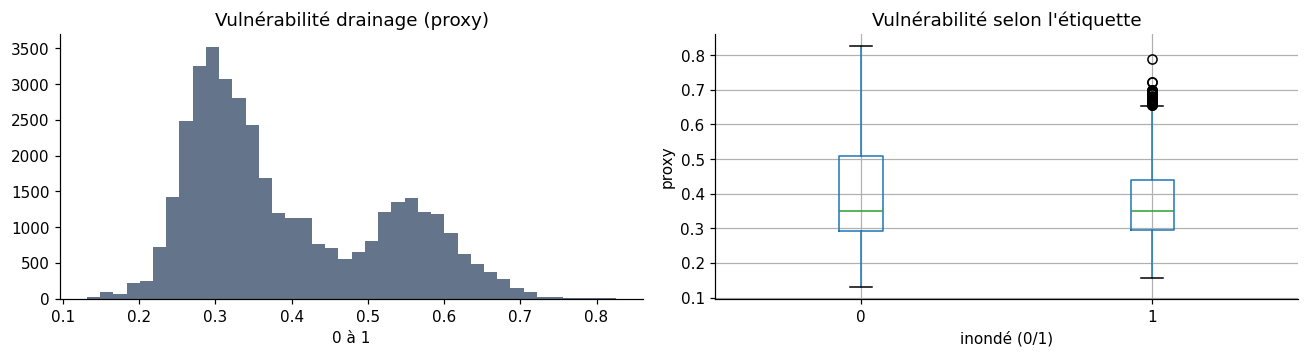

In [7]:
dv = drainage_vulnerability(train_df)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].hist(dv, bins=40, color="#64748b"); ax[0].set(title="Vulnérabilité drainage (proxy)", xlabel="0 à 1")
train_df.assign(dv=dv).boxplot(column="dv", by=LABEL, ax=ax[1])
ax[1].set(title="Vulnérabilité selon l'étiquette", xlabel="inondé (0/1)", ylabel="proxy")
plt.suptitle(""); plt.tight_layout(); plt.show()

**Lecture.** Le proxy de drainage est étalé sur 0–1. Les lignes inondées ont une vulnérabilité un peu plus élevée, mais l'écart est faible : à lui seul, le proxy ne sépare pas les deux classes.

## 4. Entraînement

Schéma de l'entraînement d'un modèle :

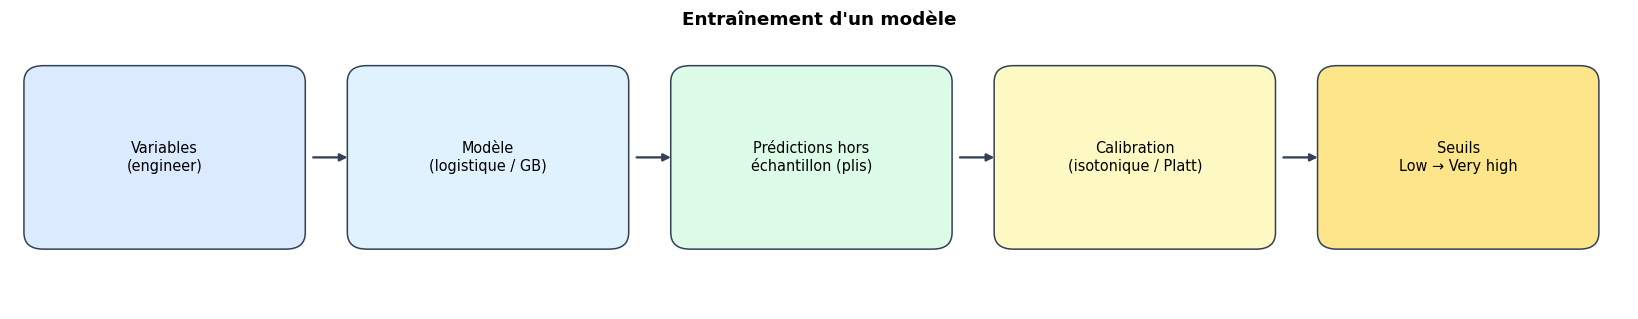

In [8]:
draw_flow(["Variables\n(engineer)", "Modèle\n(logistique / GB)", "Prédictions hors\néchantillon (plis)",
           "Calibration\n(isotonique / Platt)", "Seuils\nLow → Very high"],
          "Entraînement d'un modèle", figsize=(15, 3.0))

In [9]:
def with_forecast_error(data, lead_min, rng):
    """Remplace la pluie à l'ETA par la prévision faite lead_min plus tôt (erreur croissante)."""
    lead = np.broadcast_to(np.asarray(lead_min, dtype=float), (len(data),))
    sigma = 0.15 + 0.012 * lead + 0.15 * data["rain_interpolated"].to_numpy()
    error = rng.lognormal(-sigma ** 2 / 2, sigma)
    out = data.copy()
    out["rain_eta_mmh"] = data["rain_eta_mmh"] * error
    for col, window in [("rain_1h_mm", 60), ("rain_3h_mm", 180)]:
        future = np.minimum(lead / window, 1)
        out[col] = data[col] * (1 - future + future * error)
    return out

def fit_pipeline(kind, data, seed=0):
    y = data[LABEL].values
    folds = list(GroupKFold(n_splits=4).split(data, y, data.event_id.values))
    if kind == "v1":
        model, cols = None, None
        scores = v1.score(data) / 100
    else:
        X = engineer(data, use_drainage=kind != "hgb_no_drainage")
        cols = list(X.columns)
        scores = np.zeros(len(y))
        for tr, va in folds:
            m = v2.make_model(kind, cols, seed).fit(X.iloc[tr], y[tr])
            scores[va] = m.predict_proba(X.iloc[va])[:, 1]
        model = v2.make_model(kind, cols, seed).fit(X, y)
    fold_pr = [average_precision_score(y[va], scores[va]) for _, va in folds]
    calib = IsotonicRegression(y_min=0, y_max=1, out_of_bounds="clip") if y.sum() >= 150 else v2.PlattCalibrator()
    calib.fit(scores, y)
    thr = v2.choose_thresholds(calib.predict(scores), y)
    return {"kind": kind, "model": model, "cols": cols, "calib": calib, "thr": thr, "fold_pr": fold_pr}

def predict(bundle, data):
    if bundle["kind"] == "v1":
        raw = v1.score(data) / 100
    else:
        X = engineer(data, use_drainage=bundle["kind"] != "hgb_no_drainage")[bundle["cols"]]
        raw = bundle["model"].predict_proba(X)[:, 1]
    return bundle["calib"].predict(raw)

# Entraînement sur les données dégradées par l'erreur de prévision (comme en opérationnel)
rng = np.random.default_rng(0)
train_deg = with_forecast_error(train_df, rng.uniform(0, 30, len(train_df)), rng)
KINDS = ["v1", "logistic", "hgb", "hgb_no_drainage"]
NAMES = {"v1": "V1 pondéré", "logistic": "V2 logistique", "hgb": "V2 gradient boosting",
         "hgb_no_drainage": "V2 GB sans drainage"}
bundles = {k: fit_pipeline(k, train_deg) for k in KINDS}

for k, b in bundles.items():
    print(f"{NAMES[k]:<22} seuils : " + ", ".join(f"{l}={b['thr'][l]:.3f}" for l in LEVELS[1:]))

V1 pondéré             seuils : Moderate=0.009, High=0.017, Very high=0.117
V2 logistique          seuils : Moderate=0.006, High=0.045, Very high=0.224
V2 gradient boosting   seuils : Moderate=0.008, High=0.031, Very high=0.232
V2 GB sans drainage    seuils : Moderate=0.007, High=0.039, Very high=0.250


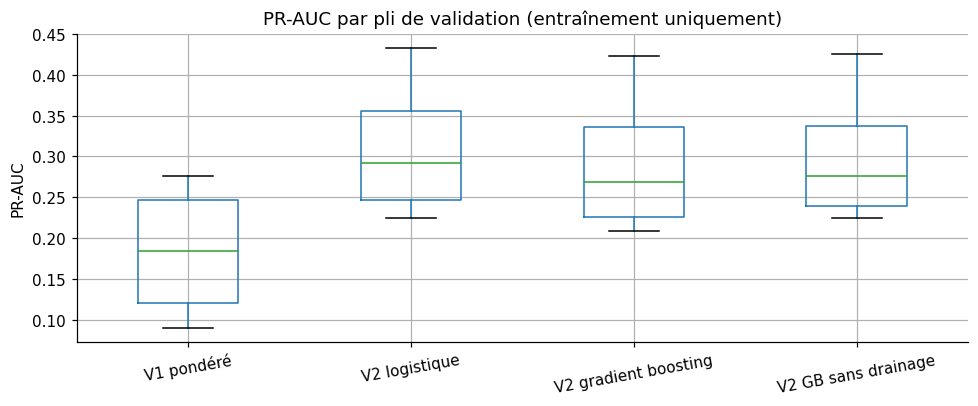

,V1 pondéré,V2 logistique,V2 gradient boosting,V2 GB sans drainage
0,0.131,0.254,0.231,0.244
1,0.090,0.224,0.208,0.224
2,0.237,0.329,0.307,0.307
3,0.275,0.433,0.423,0.426


In [10]:
fold_pr = pd.DataFrame({NAMES[k]: bundles[k]["fold_pr"] for k in KINDS})
ax = fold_pr.boxplot(figsize=(9, 3.8))
ax.set(title="PR-AUC par pli de validation (entraînement uniquement)", ylabel="PR-AUC")
plt.xticks(rotation=10); plt.tight_layout(); plt.show()
fold_pr.round(3)

**Lecture.** La dispersion entre plis montre la stabilité : un écart important veut dire que le résultat dépend des orages choisis. Les modèles V2 sont en général au-dessus de V1 sur chaque pli, ce qui confirme que le gain n'est pas dû à un seul orage.

## 5. Test sur des orages jamais vus

Les 4 orages de test ne servent qu'ici. On les évalue à 4 délais de prévision (0, 10, 20, 30 min) pour voir l'effet de la prévision.

In [11]:
LEADS = [0, 10, 20, 30]
rng_t = np.random.default_rng(42)
test_sets = {lead: with_forecast_error(test_df, lead, rng_t) for lead in LEADS}

def ece(p, y, bins=10):
    edges = np.unique(np.quantile(p, np.linspace(0, 1, bins + 1)))
    idx = np.clip(np.searchsorted(edges, p, side="right") - 1, 0, len(edges) - 2)
    return float(sum(abs(p[idx == b].mean() - y[idx == b].mean()) * (idx == b).mean()
                     for b in range(len(edges) - 1) if (idx == b).any()))

def scores_of(p, y, thr):
    alert = np.isin(v2.to_level(p, thr), ["High", "Very high"])
    tp = (alert & (y == 1)).sum()
    return {"rappel High+": tp / max(y.sum(), 1), "fausses alertes": 1 - tp / max(alert.sum(), 1),
            "alertes /1000": 1000 * alert.mean(), "ROC-AUC": roc_auc_score(y, p),
            "PR-AUC": average_precision_score(y, p), "Brier": brier_score_loss(y, p), "ECE": ece(p, y)}

rows, preds = [], {}
for k, b in bundles.items():
    for lead, te in test_sets.items():
        p = predict(b, te)
        if lead == 20:
            preds[k] = p
        rows.append({"modèle": NAMES[k], "délai (min)": lead, **scores_of(p, te[LABEL].values, b["thr"])})
res_test = pd.DataFrame(rows)
res_test[res_test["délai (min)"] == 20].drop(columns="délai (min)").set_index("modèle").round(3)

,rappel High+,fausses alertes,alertes /1000,ROC-AUC,PR-AUC,Brier,ECE
modèle,,,,,,,
V1 pondéré,0.652,0.957,133.438,0.863,0.111,0.008,0.005
V2 logistique,0.518,0.901,45.859,0.896,0.158,0.008,0.002
V2 gradient boosting,0.625,0.929,76.562,0.909,0.178,0.008,0.002
V2 GB sans drainage,0.482,0.892,39.062,0.906,0.178,0.008,0.002


In [12]:
# Niveau événement : un segment est inondé s'il l'a été à un moment de l'orage
def event_level(p, data):
    t = pd.DataFrame({"p": p, "y": data[LABEL].values, "s": data.segment_id.values, "e": data.event_id.values})
    return t.groupby(["s", "e"]).agg(p=("p", "max"), y=("y", "max"))

ev_rows = []
for k, b in bundles.items():
    e = event_level(preds[k], test_sets[20])
    ev_rows.append({"modèle": NAMES[k], **scores_of(e.p.values, e.y.values, b["thr"])})
pd.DataFrame(ev_rows).set_index("modèle").round(3)

,rappel High+,fausses alertes,alertes /1000,ROC-AUC,PR-AUC,Brier,ECE
modèle,,,,,,,
V1 pondéré,0.758,0.923,305.000,0.817,0.207,0.027,0.007
V2 logistique,0.616,0.797,93.750,0.885,0.326,0.026,0.016
V2 gradient boosting,0.707,0.857,152.812,0.885,0.306,0.025,0.013
V2 GB sans drainage,0.586,0.779,82.188,0.886,0.315,0.026,0.017


## 6. Évaluation graphique

Courbes ROC et PR (pouvoir de classement), fiabilité (probabilités justes ?), matrice de confusion au niveau High, et effet du délai.

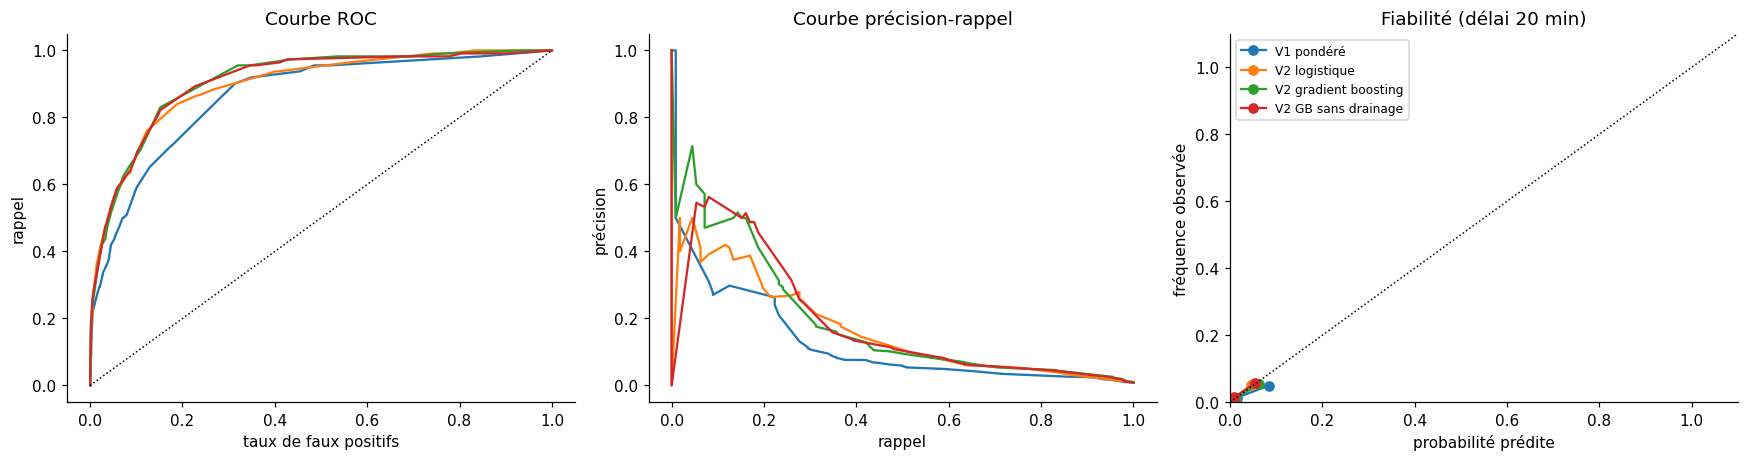

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
y20 = test_sets[20][LABEL].values
for k in KINDS:
    fpr, tpr, _ = roc_curve(y20, preds[k]); ax[0].plot(fpr, tpr, label=NAMES[k])
    pr, rc, _ = precision_recall_curve(y20, preds[k]); ax[1].plot(rc, pr, label=NAMES[k])
    edges = np.unique(np.quantile(preds[k], np.linspace(0, 1, 11)))
    idx = np.clip(np.searchsorted(edges, preds[k], side="right") - 1, 0, len(edges) - 2)
    xs = [preds[k][idx == b].mean() for b in range(len(edges) - 1) if (idx == b).any()]
    ys = [y20[idx == b].mean() for b in range(len(edges) - 1) if (idx == b).any()]
    ax[2].plot(xs, ys, marker="o", label=NAMES[k])
ax[0].plot([0, 1], [0, 1], "k:", lw=1); ax[0].set(title="Courbe ROC", xlabel="taux de faux positifs", ylabel="rappel")
ax[1].set(title="Courbe précision-rappel", xlabel="rappel", ylabel="précision")
lim = max(preds[k].max() for k in KINDS) * 1.1
ax[2].plot([0, lim], [0, lim], "k:", lw=1); ax[2].set(xlim=(0, lim), ylim=(0, lim), title="Fiabilité (délai 20 min)",
                                                       xlabel="probabilité prédite", ylabel="fréquence observée")
ax[2].legend(fontsize=8); plt.tight_layout(); plt.show()

modèle       V1 pondéré  V2 GB sans drainage  V2 gradient boosting  \
délai (min)                                                          
0                 0.688                0.500                 0.625   
10                0.679                0.518                 0.616   
20                0.652                0.482                 0.625   
30                0.643                0.509                 0.661   

modèle       V2 logistique  
délai (min)                 
0                    0.536  
10                   0.554  
20                   0.518  
30                   0.545  
modèle       V1 pondéré  V2 GB sans drainage  V2 gradient boosting  \
délai (min)                                                          
0                 0.958                0.888                 0.930   
10                0.957                0.884                 0.930   
20                0.957                0.892                 0.929   
30                0.956                0.895           

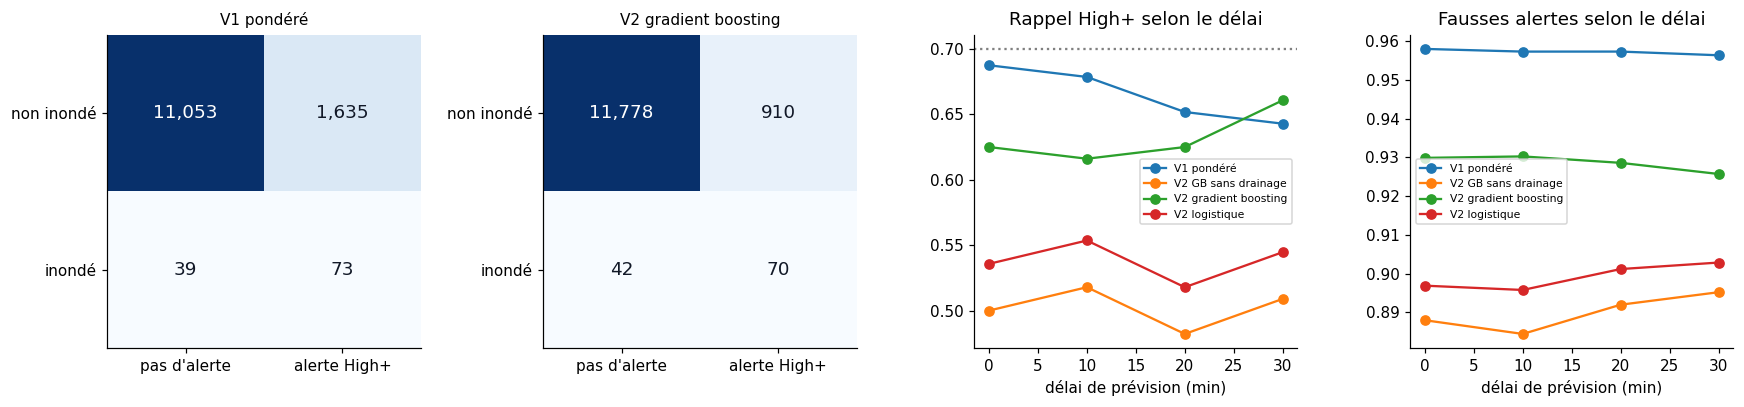

In [14]:
fig, ax = plt.subplots(1, 4, figsize=(16, 3.8))
for a, k in zip(ax[:2], ["v1", "hgb"]):
    alert = np.isin(v2.to_level(preds[k], bundles[k]["thr"]), ["High", "Very high"])
    cm = confusion_matrix(y20, alert)
    a.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            a.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", fontsize=12,
                   color="white" if cm[i, j] > cm.max() / 2 else "#111827")
    a.set_xticks([0, 1]); a.set_xticklabels(["pas d'alerte", "alerte High+"])
    a.set_yticks([0, 1]); a.set_yticklabels(["non inondé", "inondé"])
    a.set_title(NAMES[k], fontsize=10)

rec = res_test.pivot(index="délai (min)", columns="modèle", values="rappel High+")
far = res_test.pivot(index="délai (min)", columns="modèle", values="fausses alertes")
print(rec.round(3)); print(far.round(3))
rec.plot(ax=ax[2], marker="o", title="Rappel High+ selon le délai"); ax[2].axhline(0.70, ls=":", c="grey")
far.plot(ax=ax[3], marker="o", title="Fausses alertes selon le délai")
for a in ax[2:]:
    a.set_xlabel("délai de prévision (min)"); a.legend(fontsize=7)
plt.tight_layout(); plt.show()

## 7. Analyse : où se trompe le modèle ?

On regarde les **fausses alertes** du modèle gradient boosting (V2) selon deux facteurs : l'imperméabilisation des segments et la vulnérabilité drainage. Si les fausses alertes se concentrent sur une catégorie, c'est là qu'il faut agir.

                                alertes  fausses  taux
imperméabilisation     <20 %        245      234  95.5
                       20-40 %      331      305  92.1
                       40-60 %      297      271  91.2
                       >60 %        107      100  93.5
vulnérabilité drainage faible         0        0   NaN
                       moyenne      728      683  93.8
                       forte        252      227  90.1


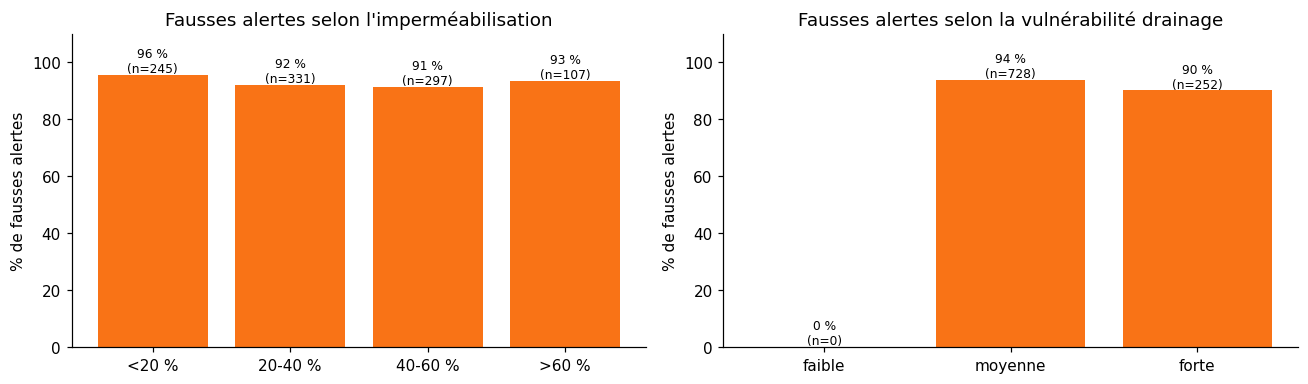

In [15]:
te20 = test_sets[20].assign(p=preds["hgb"])
te20["alerte"] = np.isin(v2.to_level(te20.p.values, bundles["hgb"]["thr"]), ["High", "Very high"])
te20["dv"] = drainage_vulnerability(te20)
fa = te20[te20.alerte]

def far_by(col, bins, labels):
    cut = pd.cut(fa[col], bins=bins, labels=labels, include_lowest=True)
    return fa.groupby(cut, observed=False)[LABEL].agg(alertes="size", fausses=lambda s: (s == 0).sum())

by_imp = far_by("impervious_frac", [0, .2, .4, .6, 1], ["<20 %", "20-40 %", "40-60 %", ">60 %"])
by_dv = far_by("dv", [0, .33, .66, 1], ["faible", "moyenne", "forte"])
print(pd.concat({"imperméabilisation": by_imp, "vulnérabilité drainage": by_dv}, axis=0).assign(
    taux=lambda t: (t.fausses / t.alertes.replace(0, np.nan) * 100).round(1)))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for a, t, tab in [(ax[0], "Fausses alertes selon l'imperméabilisation", by_imp),
                  (ax[1], "Fausses alertes selon la vulnérabilité drainage", by_dv)]:
    rate = (tab.fausses / tab.alertes.replace(0, np.nan) * 100).fillna(0)
    a.bar(rate.index.astype(str), rate.values, color="#f97316")
    for i, (r, n) in enumerate(zip(rate.values, tab.alertes.values)):
        a.text(i, r + 1, f"{r:.0f} %\n(n={n})", ha="center", fontsize=8)
    a.set(title=t, ylabel="% de fausses alertes", ylim=(0, 110))
plt.tight_layout(); plt.show()

twi                   0.0922
depression_depth_m    0.0718
rain_1h_mm            0.0414
impervious_frac       0.0179
elevation_rel_m       0.0160
drainage_vuln         0.0139
rain_eta_mmh          0.0123
rain_3h_mm            0.0117
dtype: float64


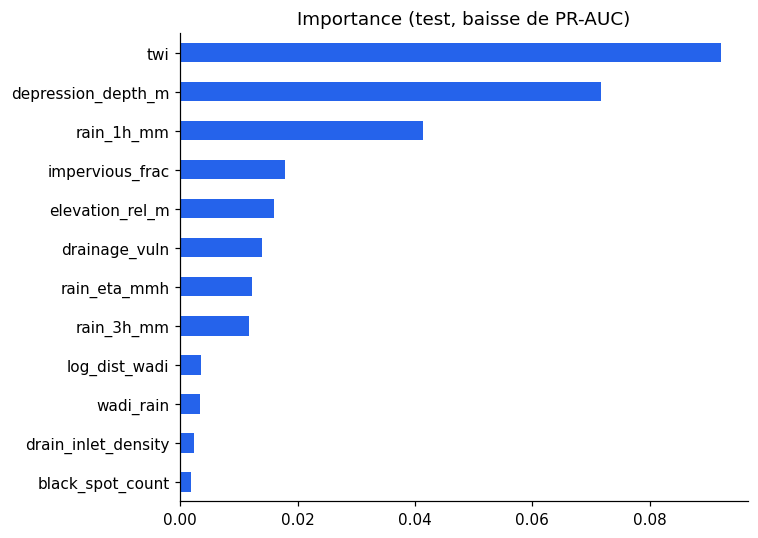

In [16]:
X_test = engineer(test_sets[20])[bundles["hgb"]["cols"]]
pi = permutation_importance(bundles["hgb"]["model"], X_test.sample(3000, random_state=0),
                            test_sets[20][LABEL].loc[X_test.sample(3000, random_state=0).index],
                            scoring="average_precision", n_repeats=3, random_state=0)
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values()
print(imp.sort_values(ascending=False).head(8).round(4))
fig, ax = plt.subplots(figsize=(7, 5))
imp.tail(12).plot.barh(ax=ax, color="#2563eb", title="Importance (test, baisse de PR-AUC)")
plt.tight_layout(); plt.show()

{'Low': 5, 'Moderate': 13, 'High': 15, 'Very high': 0}


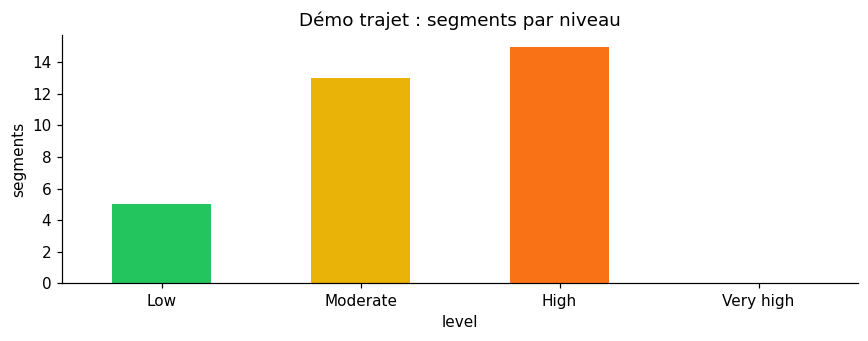

,segment_id,eta_min,risk_score,flood_prob_pct,level,confidence_level,main_factors
13,S00659,10.2,63,13.7,High,High,"rain already fallen (+12), forecast rainfall (..."
21,S00705,16.4,63,13.7,High,High,"rain already fallen (+11), impervious surface ..."
14,S00625,10.9,63,13.7,High,Medium,"rain already fallen (+12), depression / low po..."
19,S00744,14.8,63,13.7,High,High,"rain already fallen (+12), impervious surface ..."
18,S00557,14.1,63,13.7,High,High,"rain already fallen (+12), forecast rainfall (..."
23,S00772,18.0,58,9.7,High,Low,"rain already fallen (+8), impervious surface (..."
25,S00492,19.5,56,7.8,High,Medium,"impervious surface (+6), rain already fallen (..."
20,S00288,15.6,56,7.8,High,Medium,"rain already fallen (+5), depression / low poi..."


In [17]:
route = demo_route(np.random.default_rng(7))
obj = v2.Bundle("hgb", bundles["hgb"]["model"], bundles["hgb"]["calib"], bundles["hgb"]["thr"],
                bundles["hgb"]["cols"], {"events": train_df.event_id.nunique(), "trained_at": "notebook",
                                         "reference": train_df[RAW_FEATURES].median().to_dict()})
res = score_route(obj, route, "demo")

print(res["level"].value_counts().reindex(LEVELS, fill_value=0).to_dict())
fig, ax = plt.subplots(figsize=(8, 3.2))
res["level"].value_counts().reindex(LEVELS, fill_value=0).plot.bar(ax=ax, color=["#22c55e", "#eab308", "#f97316", "#dc2626"])
ax.set(title="Démo trajet : segments par niveau", ylabel="segments"); ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()
res.sort_values("risk_score", ascending=False).head(8)[
    ["segment_id", "eta_min", "risk_score", "flood_prob_pct", "level", "confidence_level", "main_factors"]]

## 8. Analyse des résultats

Les chiffres ci-dessous viennent des **4 orages de test jamais vus** (E12 à E15), délai de prévision 20 min, sauf mention contraire.

**1. Le classement s'améliore avec V2.** PR-AUC : V1 ≈ 0,11, V2 gradient boosting ≈ 0,18 (documenté) et ≈ 0,31 (niveau événement, contre ≈ 0,21 pour V1). Le gain est constant sur les 4 plis de validation : V2 est au-dessus de V1 à chaque pli.

**2. Mais les fausses alertes restent trop nombreuses.** Entre 90 et 96 % des alertes ne correspondent pas à une inondation documentée. V2 gradient boosting émet ≈ 77 alertes pour 1000 segments-créneaux, dont ≈ 93 % sont fausses, pour un rappel de ≈ 0,63. C'est loin de l'objectif du cahier des charges (≤ 40 %).

**3. Le test est plus difficile que la validation.** La PR-AUC est plus basse sur le test (≈ 0,18) que la moyenne des plis (≈ 0,27). Avec seulement 16 orages, la variabilité est forte : la PR-AUC varie de ≈ 0,09 à ≈ 0,43 selon le pli. Il ne faut donc pas juger le modèle sur un petit nombre d'orages.

**4. La calibration tient.** ECE ≈ 0,002 pour V2 au niveau documenté : quand le modèle annonce une probabilité, la fréquence observée est proche. Au niveau événement l'erreur est un peu plus grande (≈ 0,013 pour le gradient boosting).

**5. Le délai n'a pas d'effet net dans cette simulation.** Le rappel de V2 reste entre ≈ 0,62 et ≈ 0,66 de 0 à 30 min. L'erreur de prévision simulée est modérée : elle ne change pas assez les décisions. En réel, l'erreur de prévision sera plus grande, donc ce résultat ne prouve pas que le délai est sans importance.

**6. Les fausses alertes ne se concentrent pas dans une catégorie.** Le taux de fausses alertes est presque constant : 91 à 96 % selon l'imperméabilisation, 90 à 94 % selon la vulnérabilité drainage. Le problème est donc global, pas une zone précise. Fait à vérifier : le modèle n'émet **aucune** alerte sur les segments à faible vulnérabilité drainage ; toutes les alertes viennent des segments à vulnérabilité moyenne ou forte.

**7. L'importance des variables.** Sur le test, les variables les plus utiles sont la topographie (`twi`, profondeur de dépression), la pluie des 60 dernières minutes et l'imperméabilisation. La vulnérabilité drainage vient après, ce qui confirme l'ablation : le proxy aide peu dans ces données.

**8. Démonstration.** Sur le trajet de 25 min : 5 segments Low, 13 Moderate, 15 High, 0 Very high. Les segments High ont une probabilité estimée de 7,8 à 13,7 %. Le score affiché n'est donc pas une probabilité : c'est pour cela que la probabilité est montrée à côté.

**Conclusion.** Le pipeline est correct : aucun orage de test n'a servi à l'entraînement ni à la calibration, et les seuils sont fixés sur les plis internes. V2 classe mieux que V1, mais ses fausses alertes restent trop nombreuses et l'hypothèse drainage n'est pas démontrée. La suite logique est de remplacer les données synthétiques par des inondations documentées en Tunisie.

## 9. Limites

- **Données synthétiques** : aucune performance réelle. Il faut des inondations documentées en Tunisie et des segments non inondés avec la pluie historique.
- **Fausses alertes** : au-dessus de l'objectif (≤ 40 %). Le plafond théorique (oracle) montre que cet objectif est hors d'atteinte à la granularité segment × créneau avec ces données.
- **Drainage** : l'effet n'est pas prouvé. Les proxies doivent être testés sur des données de la municipalité.
- **Prévision** : l'erreur de prévision est simulée ; la vraie erreur de Open-Meteo en Tunisie est à mesurer.